In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import xgboost as xgb
import seaborn as sns


from sklearn.metrics import mean_squared_error


import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

In [2]:
df=pd.read_csv(r"C:\Users\SOLOMON\Downloads\Telegram Desktop\weatherdata.csv")

In [3]:
df = df.drop(
    columns=['Longitude', 'Latitude', 'Elevation'])

In [4]:
df = df.set_index('Date')

In [5]:
df.index=pd.to_datetime(df.index, dayfirst=True)

C:\Users\SOLOMON\AppData\Local\Temp\ipykernel_19540\2162519006.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df.index=pd.to_datetime(df.index, dayfirst=True)


In [6]:
df

,Max Temperature,Min Temperature,Wind,Relative Humidity,Solar,Precipitation
Date,,,,,,
1979-01-01,30.713,11.719,1.595418,0.418255,23.386395,0.000000
1979-02-01,30.872,10.407,1.726672,0.432899,25.572441,0.000000
1979-03-01,28.579,10.795,1.870545,0.456901,25.568213,0.000000
1979-04-01,29.383,10.712,1.704374,0.463286,25.659900,0.000000
1979-05-01,30.837,9.487,1.719667,0.394840,25.737013,0.000000
...,...,...,...,...,...,...
2014-07-27,21.351,15.630,1.123813,0.898494,15.266439,33.345219
2014-07-28,25.326,15.266,1.128937,0.840943,21.724500,11.767387
2014-07-29,23.138,13.402,1.297933,0.799027,18.358496,1.153566


<Axes: title={'center': 'Weather Forcast'}, xlabel='Date'>

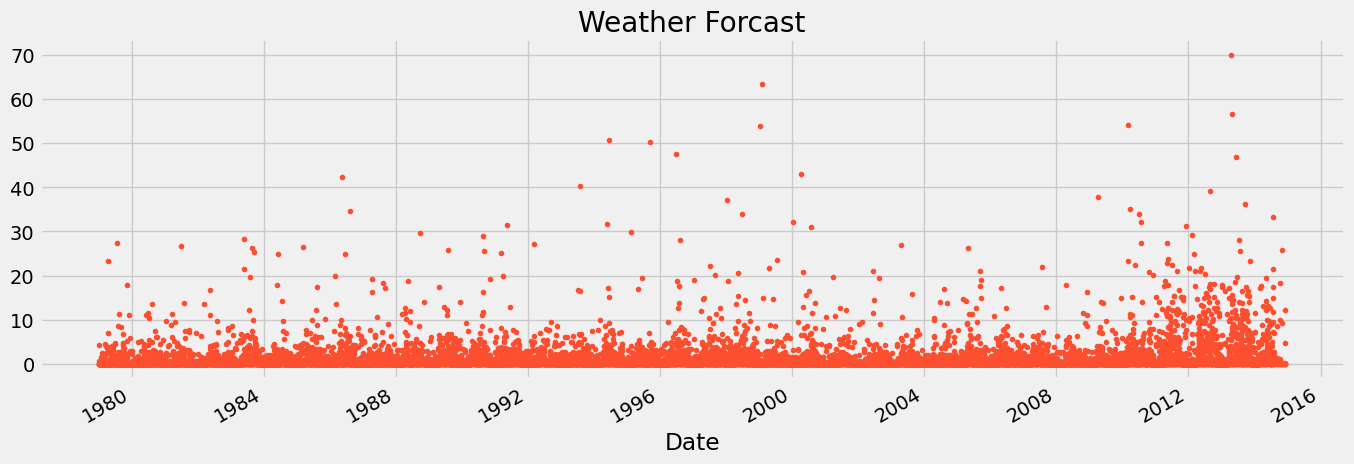

In [7]:
color_pallete = sns.color_palette()
df["Precipitation"].plot(style='.', figsize=(15,5), color= color_pallete[1], title="Weather Forcast")

In [9]:
train = df.loc[df.index<= '2014-07-01']
test = df.loc[df.index >= '2014-07-02']

In [10]:
tr=train["Precipitation"]
te=test["Precipitation"]

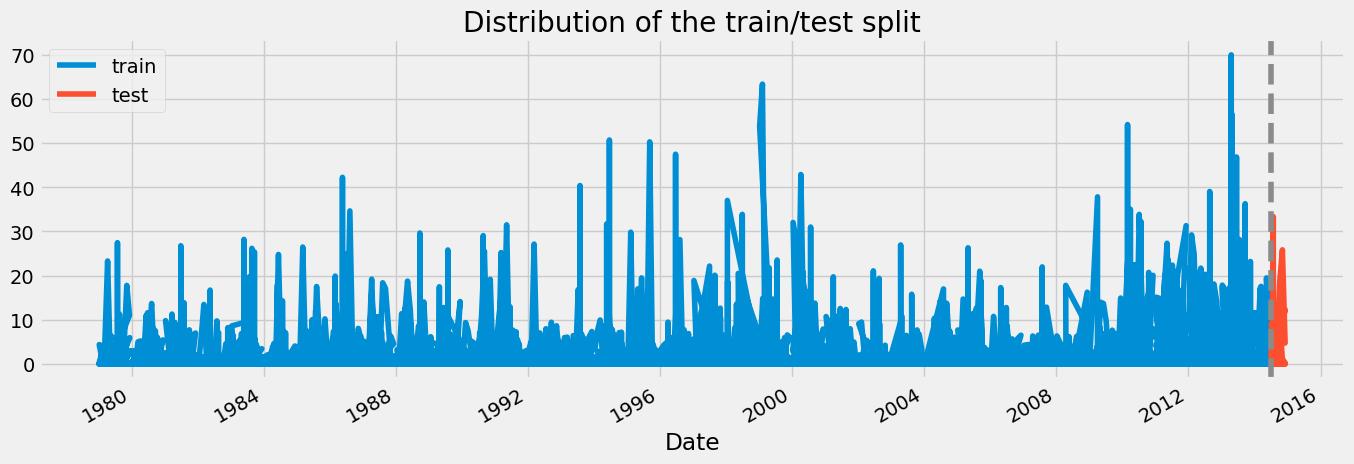

In [11]:
fig, ax = plt.subplots(figsize = (15, 5))
tr.plot(ax = ax, label = "Training", title = "Distribution of the train/test split")
te.plot(ax = ax, label = "Testing")
ax.axvline('2014-7-02', color = color_pallete[4], ls = '--')
ax.legend(['train','test'])
plt.show()

In [12]:
def feature_extraction(df):
    df = df.copy()
    
    
    df['dayofweek'] = df.index.day_of_week
    df['quarter'] = df.index.quarter
    df['month'] = df.index.month
    df['dayofyear'] = df.index.day_of_year
    df['year'] = df.index.year
    iso = df.index.isocalendar()

    df['weekofyear'] = iso.week
    df['week'] = iso.week
    df['monthofyear'] = df.index.month
    return df
df = feature_extraction(df)

In [13]:
df.columns

Index(['Max Temperature', 'Min Temperature', 'Wind', 'Relative Humidity',
       'Solar', 'Precipitation', 'dayofweek', 'quarter', 'month', 'dayofyear',
       'year', 'weekofyear', 'week', 'monthofyear'],
      dtype='object')

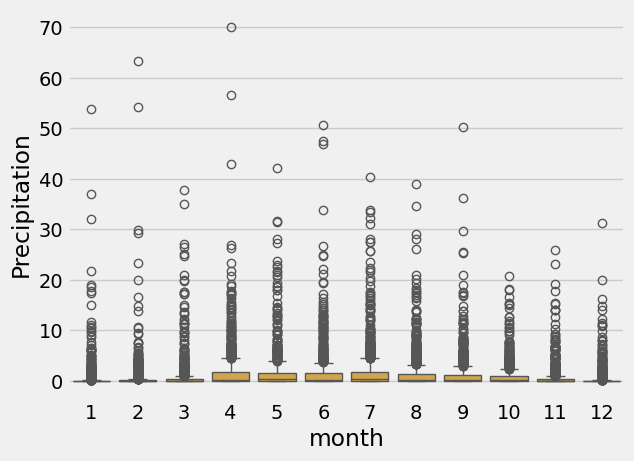

In [14]:
sns.boxplot(data=df, x='month', y = 'Precipitation', color=color_pallete[2])
ax.set_title('Month')
plt.show()

In [19]:
df

,Max Temperature,Min Temperature,Wind,Relative Humidity,Solar,Precipitation,dayofweek,quarter,month,dayofyear,year,weekofyear,week,monthofyear
Date,,,,,,,,,,,,,,
1979-01-01,30.713,11.719,1.595418,0.418255,23.386395,0.000000,0,1,1,1,1979,1,1,1
1979-02-01,30.872,10.407,1.726672,0.432899,25.572441,0.000000,3,1,2,32,1979,5,5,2
1979-03-01,28.579,10.795,1.870545,0.456901,25.568213,0.000000,3,1,3,60,1979,9,9,3
1979-04-01,29.383,10.712,1.704374,0.463286,25.659900,0.000000,6,2,4,91,1979,13,13,4
1979-05-01,30.837,9.487,1.719667,0.394840,25.737013,0.000000,1,2,5,121,1979,18,18,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2014-07-27,21.351,15.630,1.123813,0.898494,15.266439,33.345219,6,3,7,208,2014,30,30,7
2014-07-28,25.326,15.266,1.128937,0.840943,21.724500,11.767387,0,3,7,209,2014,31,31,7
2014-07-29,23.138,13.402,1.297933,0.799027,18.358496,1.153566,1,3,7,210,2014,31,31,7


In [20]:

target = 'Precipitation'
corr = df.corr(numeric_only=True)[target].abs()

selected_features = corr[
    corr > 0.1
].index.tolist()

selected_features.remove(target)

selected_features

['Max Temperature',
 'Min Temperature',
 'Wind',
 'Relative Humidity',
 'Solar',
 'year']

In [21]:
train = feature_extraction(train)
test = feature_extraction(test)

In [22]:
X_train = train[selected_features]
Y_train = train[target]
X_test = test[selected_features]
Y_test = test[target]

In [27]:
regression = xgb.XGBRegressor(n_estimators = 200, early_stopping_rounds = True, learning_rate = 0.001)
regression.fit(X_train, Y_train, eval_set = [(X_train, Y_train), (X_test, Y_test)], verbose = True)

[0]	validation_0-rmse:3.32252	validation_1-rmse:7.65928
[1]	validation_0-rmse:3.32076	validation_1-rmse:7.65478
[2]	validation_0-rmse:3.31900	validation_1-rmse:7.65025
[3]	validation_0-rmse:3.31725	validation_1-rmse:7.64575
[4]	validation_0-rmse:3.31550	validation_1-rmse:7.64123
[5]	validation_0-rmse:3.31375	validation_1-rmse:7.63675
[6]	validation_0-rmse:3.31200	validation_1-rmse:7.63224
[7]	validation_0-rmse:3.31025	validation_1-rmse:7.62777
[8]	validation_0-rmse:3.30851	validation_1-rmse:7.62327
[9]	validation_0-rmse:3.30677	validation_1-rmse:7.61878
[10]	validation_0-rmse:3.30503	validation_1-rmse:7.61432
[11]	validation_0-rmse:3.30330	validation_1-rmse:7.60984
[12]	validation_0-rmse:3.30156	validation_1-rmse:7.60539
[13]	validation_0-rmse:3.29983	validation_1-rmse:7.60092
[14]	validation_0-rmse:3.29810	validation_1-rmse:7.59648
[15]	validation_0-rmse:3.29638	validation_1-rmse:7.59202
[16]	validation_0-rmse:3.29465	validation_1-rmse:7.58759
[17]	validation_0-rmse:3.29293	validation

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,True
,enable_categorical,True
,eval_metric,None


In [28]:
feature_stat = pd.DataFrame(data = regression.feature_importances_, 
             index= regression.feature_names_in_,
            columns = ['importance'])

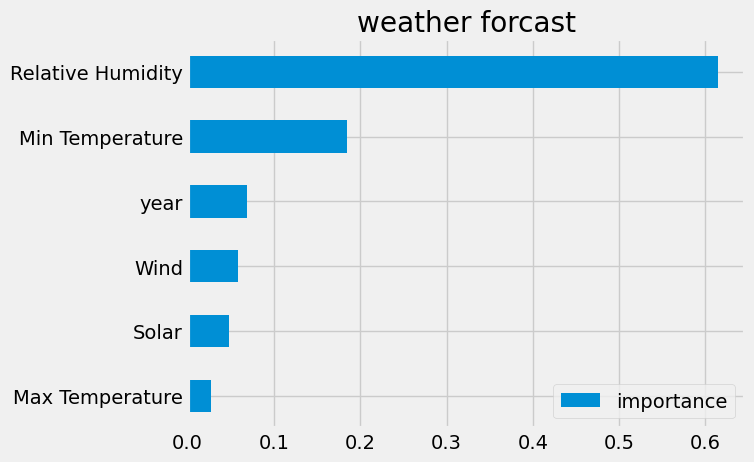

In [29]:
feature_stat.sort_values('importance').plot(kind = 'barh', title = 'weather forcast')
plt.show()

In [30]:
test['Prediction'] = regression.predict(X_test)

In [35]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge,Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.tsa.arima.model import ARIMA

sns.set_theme(style="whitegrid")

In [36]:
predictions = {}
results = []

In [41]:
ml_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=100.0, max_iter=10000, random_state=42),
    "KNN": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "regression":  xgb.XGBRegressor(n_estimators = 200, early_stopping_rounds = True, learning_rate = 0.001),

    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

In [46]:
for name, model in ml_models.items():
  model.fit(X_train, Y_train)
  preds = model.predict(X_test)
  predictions[name] = pd.Series(preds, index=Y_test.index)

  mae = mean_absolute_error(Y_test, preds)
  rmse = np.sqrt(mean_squared_error(Y_test, preds))
  r2 = r2_score(Y_test, preds)
  results.append({"Model": name, "MAE": mae, "RMSE": rmse, "R2 Score": r2})

ValueError: Must have at least 1 validation dataset for early stopping.

In [ ]:
try:
  arima_model = ARIMA(y_train, order=(7, 1, 1)).fit()
  arima_preds = arima_model.forecast(steps=test_days)
  predictions["ARIMA(7,1,1)"] = pd.Series(
      arima_preds.values, index=y_test.index
  )

  mae = mean_absolute_error(y_test, arima_preds)
  rmse = np.sqrt(mean_squared_error(y_test, arima_preds))
  r2 = r2_score(y_test, arima_preds)
  results.append({
      "Model": "ARIMA(7,1,1)",
      "MAE": mae,
      "RMSE": rmse,
      "R2 Score": r2,
  })
except Exception as e:
  print(f"ARIMA fitting skipped due to: {e}")

In [ ]:
results_df = pd.DataFrame(results).sort_values(by="RMSE")
print("\n=== Time Series Model Comparison ===")
print(results_df.to_string(index=False))